# P7.14 — Passa-faixa de comprimento mínimo com janela de Kaiser

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., pp. 379–380 · DTA §2.1 (item 6), §3.1.D e §4 (Resolução P7.14).

> *We wish to use the Kaiser window method to design a linear-phase FIR digital filter that meets the following specifications: 0 ≤ |H(e^{jω})| ≤ 0.01, 0 ≤ ω ≤ 0.25π; 0.95 ≤ |H(e^{jω})| ≤ 1.05, 0.35π ≤ ω ≤ 0.65π; 0 ≤ |H(e^{jω})| ≤ 0.01, 0.75π ≤ ω ≤ π. Determine the minimum length impulse response h(n) of such a filter. Provide a plot containing subplots of the amplitude response and the magnitude response in dB. Do not use the fir1 function.*

| Faixa | Ganho ideal | Tolerância |
|---|---|---|
| $0 \le \omega \le 0.25\pi$ | 0 | $\delta_2 = 0.01$ |
| $0.35\pi \le \omega \le 0.65\pi$ | 1 | $\delta_1 = 0.05$ |
| $0.75\pi \le \omega \le \pi$ | 0 | $\delta_2 = 0.01$ |

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método de Kaiser

O procedimento é o mesmo do P7.13:

$$\delta = \min(0.05, 0.01) = 0.01 \;\Rightarrow\; A_s = 40\ \text{dB}, \qquad \beta = 0.5842(19)^{0.4} + 0.07886\cdot 19 = 3.3953$$

$$M \approx \left\lceil \frac{40 - 7.95}{2.285 \cdot 0.1\pi} \right\rceil + 1 = \lceil 44.65 \rceil + 1 = 46$$

**Paridade (decisão D4).** O DTA força $M$ ímpar (47). Mas o Tipo 2 ($M$ par) só impõe $H_r(\pi) = 0$, e no passa-faixa $\omega = \pi$ pertence à rejeição superior, onde o ganho desejado já é zero. Logo $M$ par é admissível, e a busca do mínimo deve incluí-lo.

Cortes: $\omega_{c1} = 0.3\pi$, $\omega_{c2} = 0.7\pi$; $\alpha = (M-1)/2$, que é semi-inteiro quando $M$ é par.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from dsp_av2.fir import analysis
from dsp_av2.fir.design import design_kaiser
from dsp_av2.specs import P7_14 as SPEC
from dsp_av2.validation import validate_fir_tolerance
from exercises import p7_14

e = p7_14.estimate()
print(f"A_s = {e.params['As_design_dB']:.4f} dB,  β = {e.params['beta']:.4f},  estimativa M = {e.M}")

A_s = 40.0000 dB,  β = 3.3953,  estimativa M = 46


## 2. Busca do comprimento mínimo (β fixo, pares e ímpares)

In [3]:
s = p7_14.search()
print(" M  Tipo   rej. inf.   passagem   rej. sup.   atende?")
for M in range(43, 49):
    dm = design_kaiser(SPEC, M=M)
    r = validate_fir_tolerance(dm)
    c = [ch.measured for ch in r.checks]
    print(f"{M:3d}   {analysis.linear_phase_type(dm.h)}    {c[0]:.5f}    {c[1]:.5f}    {c[2]:.5f}    {'sim' if r.passed else 'não'}")
print(f"\nComprimento mínimo verificado: M = {s.M_min}")

 M  Tipo   rej. inf.   passagem   rej. sup.   atende?
 43   1    0.02031    0.01839    0.02031    não
 44   2    0.01705    0.01842    0.01290    não
 45   1    0.01227    0.01470    0.01227    não
 46   2    0.00765    0.01294    0.00978    sim
 47   1    0.00890    0.00869    0.00890    sim
 48   2    0.00872    0.00815    0.00661    sim

Comprimento mínimo verificado: M = 46


A estimativa ($M = 46$) acerta desta vez, e nenhum comprimento menor atende. O $M = 47$ do DTA também atende, mas não é o mínimo.

No Tipo 2 os desvios nas duas rejeições deixam de ser simétricos: o zero forçado em $\omega = \pi$ "puxa" a rejeição superior. Com $M = 46$, essa é a faixa crítica (≈ 0.0098 contra o limite de 0.01).

## 3. Resultados

Pedidos: $H_r(\omega)$ e magnitude em dB, com $h(n)$ como contexto. Repare que $h(n)$ é simétrica em torno de $\alpha = 22.5$, entre duas amostras.

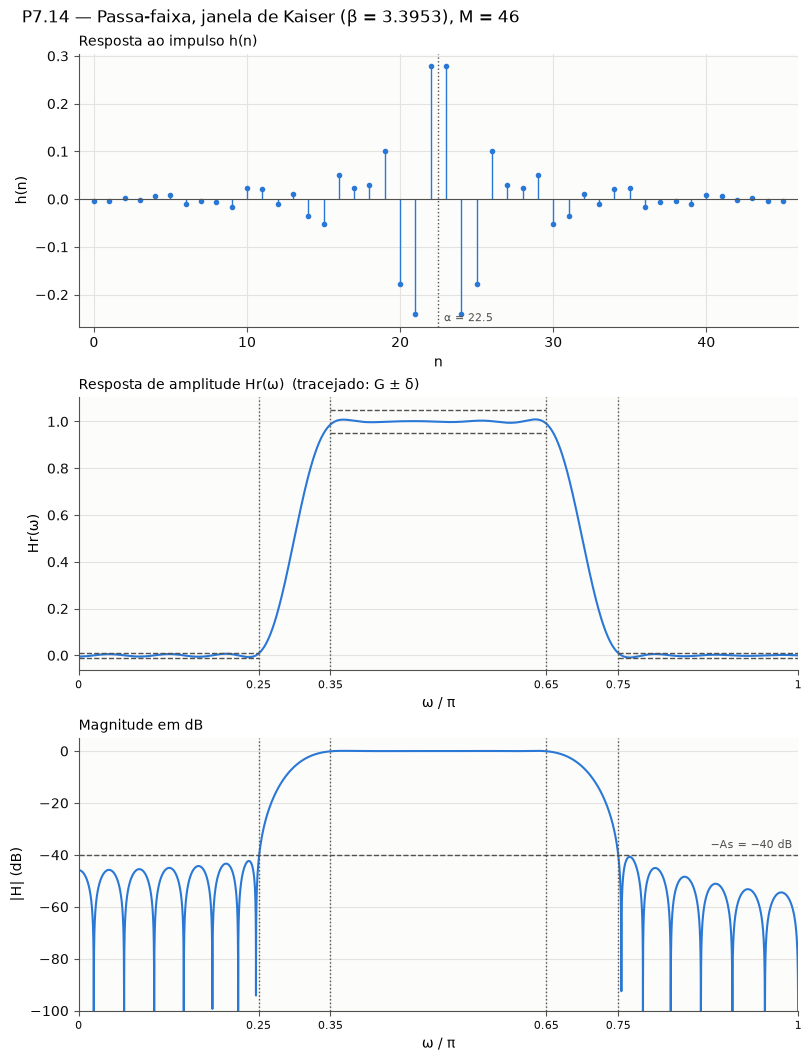

In [4]:
d = s.best
fig = p7_14.plot(d)
plt.show()

## 4. Validação contra a especificação

In [5]:
print(validate_fir_tolerance(d, n_points=200001))
print("\nHr(π) =", analysis.amplitude_response(d.h, np.array([np.pi]))[0], " (zero do Tipo 2)")

Validação P7.14 (Tipo 2 de fase linear)
  [OK  ] ||H| − 0| em [0π, 0.25π]: 0.0076 <= 0.0100  (folga +0.0024)
  [OK  ] ||H| − 1| em [0.35π, 0.65π]: 0.0129 <= 0.0500  (folga +0.0371)
  [OK  ] ||H| − 0| em [0.75π, 1π]: 0.0098 <= 0.0100  (folga +0.0002)
  Resultado: ATENDE à especificação

Hr(π) = 4.9091342259019766e-18  (zero do Tipo 2)


## 5. Conclusão

- Kaiser: $A_s = 40$ dB e $\beta = 3.3953$, valores que coincidem com o DTA.
- O comprimento mínimo verificado é **$M = 46$** (Tipo 2, $\alpha = 22.5$), igual à estimativa de Kaiser.
- O DTA dá $M = 47$ porque força $M$ ímpar. Isso não é exigido num passa-faixa: o zero do Tipo 2 em $\omega = \pi$ cai na rejeição.
- Margem crítica: rejeição superior, ≈ 0.0098 contra 0.01.